## Task 1: Data Forensics & Cleaning

### 1.1 Load and Inspect

In [154]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('pima_modified.csv')

In [155]:
display(df.head(10)) # displays the first 10 rows of the dataframe

,preg,plas,pres,skin,test,mass,pedi,age,class,hospital_id
0,6,980,58,?,?,34.0,0.430,43,0,958379
1,2,1120,75,?,0,35.7,0.148,21,0,621608
2,2,1080,64,?,0,30.8,0.158,21,0,830265
3,8,1070,80,?,?,24.6,0.856,34,0,924143
4,7,1360,90,?,0,29.9,0.210,50,0,995331
5,6,1030,72,?,190,37.7,0.324,55,0,212990
6,1,710,48,?,76,20.4,0.323,22,0,769416
7,0,1170,0,?,?,33.8,0.932,44,0,382017
8,4,1540,?,?,126,31.3,0.338,37,0,229350
9,5,1470,78,?,0,33.7,0.218,65,0,652370


In [156]:
print(df.shape) # displays the number of rows and columns in the dataframe

(768, 10)


In [157]:
print(df.dtypes) # displays the data types of each column in the dataframe

preg             int64
plas             int64
pres               str
skin               str
test               str
mass           float64
pedi           float64
age              int64
class            int64
hospital_id      int64
dtype: object


### 1.2 Missing Value Investigation

In [158]:
print((df == '?').sum()) # displays the number of occurrences of '?' in each column
df = df.replace('?', np.nan) # convert ? to NaN
for col in ['pres', 'skin', 'test']:
    df[col] = pd.to_numeric(df[col])
print(df.isna().sum())
print(df[['pres', 'skin', 'test']].isna().mean() * 100) # displays the percentage of missing values per affected column

preg            0
plas            0
pres           38
skin           38
test           38
mass            0
pedi            0
age             0
class           0
hospital_id     0
dtype: int64
preg            0
plas            0
pres           38
skin           38
test           38
mass            0
pedi            0
age             0
class           0
hospital_id     0
dtype: int64
pres    4.947917
skin    4.947917
test    4.947917
dtype: float64


In [159]:
print("--------------------------------")
print(
    df[["pres", "skin", "test"]].isna().all(axis=1).sum()
)  # returns 0: no rows have all three columns as NaN
print("--------------------------------")
print(
    df[["pres", "skin", "test"]].isna().any(axis=1).sum()
)  # returns 108: 108 rows have at least one of the three columns as NaN

# This shows that the missing values are not all in the same rows, but are scattered across different rows.

# It'll also be better to impute the missing values rather than dropping entire rows,
# as that would result in losing a lot of data (108 rows out of 768 is a significant amount).

# Imputing would also be better because only approximately 5% of the columns 'pres', 'skin', and 'test' are missing values. 
# Which means that the majority of the data is still available and valuable for analysis and modeling.

# Also because the columns 'pres' (blood pressure), 'skin' (skin thickness), 
# and 'test' (insulin) are important features for predicting diabetes.

# Since it's also just a few columns in the rows that are missing, it would be better to impute the missing values rather than the entire row, 
# as the other columns in those rows still contain valuable information that can be used for analysis and modeling.

--------------------------------
0
--------------------------------
108


#### Imputation Strategy
There are different methods of replacing missing values in a dataset:
- **Mean, median, or mode imputation**: the missing numerical values are replaced with the column's mean or median, and categorical values are replaced with mode.
- **Fixed value / constant imputation**: the missing values are replaced with a predetermined constant. Should be used when the absence of a value carries an actual meaning
- **Forward fill / backward fill**: propagates the last known value forward or the next known value backward (strictly used for time-series data).
- **Multiple imputation**: generates multiple complete datasets by estimating missing values multiple times with random variation, analyses each dataset separately, and pools the results using Rubin's rules. The standard for research and clinical datasets under Missing at Random mechanism; it accurately reflects uncertainty and prevents false-positive confidence intervals.

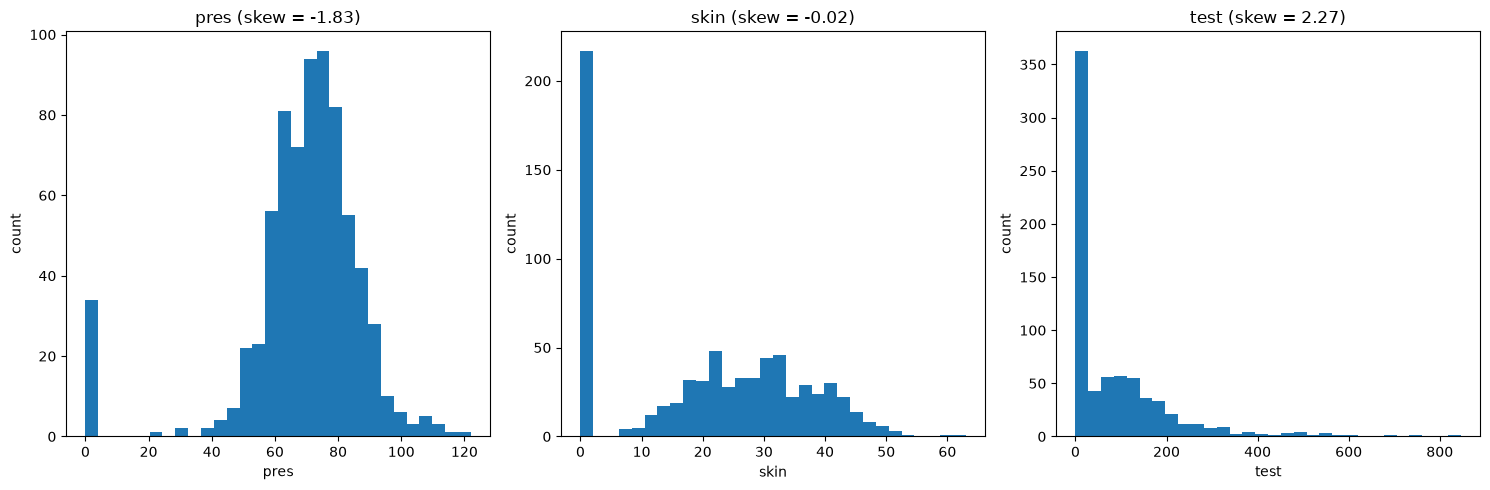

plas      5
pres     34
skin    217
test    354
mass     11
dtype: int64
----------------------------------------------------------------


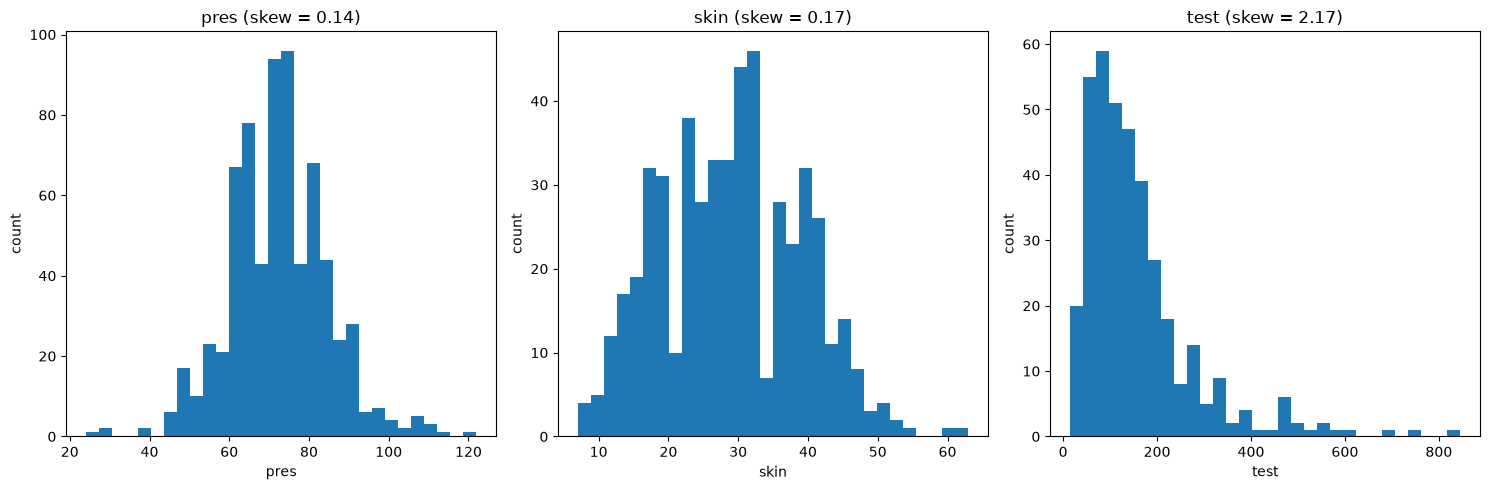

plas    0
pres    0
skin    0
test    0
mass    0
dtype: int64


In [160]:
df[['pres', 'skin', 'test']].skew()

cols = ['pres', 'skin', 'test']

fig, axes = plt.subplots(1, 3, figsize=(15, 5)) 

for ax, col in zip(axes, cols):
    ax.hist(df[col].dropna(), bins=30) # dropna() is used to ignore NaN values in the histogram; histograms can't plot NaN values
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel('count')

plt.tight_layout()
plt.show()

print((df[['plas', 'pres', 'skin', 'test', 'mass']] == 0).sum())

print('----------------------------------------------------------------')

df = df.replace(0, np.nan) # convert 0 to NaN for the specified columns

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, cols):
    ax.hist(
        df[col].dropna(), bins=30
    )  # dropna() is used to ignore NaN values in the histogram; histograms can't plot NaN values
    ax.set_title(f"{col} (skew = {df[col].skew():.2f})")
    ax.set_xlabel(col)
    ax.set_ylabel("count")

plt.tight_layout()
plt.show()

print((df[["plas", "pres", "skin", "test", "mass"]] == 0).sum())